In [284]:
# prerequisites
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision import datasets, transforms
from torch.autograd import Variable
from torchvision.utils import save_image

In [285]:
import os
import pandas as pd
from torch.utils.data import Dataset, DataLoader

class CSVDataset(Dataset):
    def __init__(self, directory, transform=None):
        self.directory = directory
        self.transform = transform

        numerical = lambda _: int(''.join(filter(str.isdigit, _)))
        self.file_names = []
        for set in os.listdir(directory):
            csv_files = sorted((f for f in os.listdir(os.path.join(directory, set)) if f.endswith('.csv')), key = numerical)
            self.file_names.extend(list(map(lambda _:os.path.join(set, _), csv_files)))
        
        # self.file_names = [os.path.join(set, f)
        #                    for set in os.listdir(directory)
        #                    for f in os.listdir(os.path.join(directory, set)) if f.endswith('.csv')]

    def __len__(self):
        return len(self.file_names)

    def __getitem__(self, idx):
        file_path = os.path.join(self.directory, self.file_names[idx])
        data = pd.read_csv(file_path, header=None, index_col=False).values
        data = data.astype('float32')
        
        if self.transform:
            data = self.transform(data)

        assert data.shape == (64, 32), f"Data shape mismatch: got {data.shape}, expected (64, 32)"

        return torch.tensor(data), 0

In [286]:
# Define transformations if any
transform = None

# Dataset directories
input_dir = './vae_input_bridge'
train_directory = input_dir
test_directory = input_dir

# Create datasets
train_dataset = CSVDataset(directory=train_directory, transform=transform)
test_dataset = CSVDataset(directory=test_directory, transform=transform)

# Data Loader (Input Pipeline)
bs = 32
train_loader = DataLoader(dataset=train_dataset, batch_size=bs, shuffle=True)
test_loader = DataLoader(dataset=test_dataset, batch_size=bs, shuffle=False)

In [287]:
reconstructed_dir = './vae_output_bridge/'
os.makedirs(reconstructed_dir, exist_ok=True)

In [288]:
class VAE(nn.Module):
    def __init__(self, x_dim, h_dim1, h_dim2, z_dim):
        super(VAE, self).__init__()
        
        # encoder part
        self.fc1 = nn.Linear(x_dim, h_dim1)
        self.fc2 = nn.Linear(h_dim1, h_dim2)
        self.fc31 = nn.Linear(h_dim2, z_dim)
        self.fc32 = nn.Linear(h_dim2, z_dim)
        # decoder part
        self.fc4 = nn.Linear(z_dim, h_dim2)
        self.fc5 = nn.Linear(h_dim2, h_dim1)
        self.fc6 = nn.Linear(h_dim1, x_dim)
        
    def encoder(self, x):
        h = F.relu(self.fc1(x))
        h = F.relu(self.fc2(h))
        return self.fc31(h), self.fc32(h) # mu, log_var
    
    def sampling(self, mu, log_var):
        std = torch.exp(0.5*log_var)
        eps = torch.randn_like(std)
        return eps.mul(std).add_(mu) # return z sample
        
    def decoder(self, z):
        h = F.relu(self.fc4(z))
        h = F.relu(self.fc5(h))
        return F.sigmoid(self.fc6(h)) 
    
    def forward(self, x):
        mu, log_var = self.encoder(x.view(-1, 64*32))
        z = self.sampling(mu, log_var)
        return self.decoder(z), mu, log_var

# build model
vae = VAE(x_dim=64*32, h_dim1= 512, h_dim2=256, z_dim=2)
if torch.cuda.is_available():
    vae.cuda()

In [289]:
vae

VAE(
  (fc1): Linear(in_features=2048, out_features=512, bias=True)
  (fc2): Linear(in_features=512, out_features=256, bias=True)
  (fc31): Linear(in_features=256, out_features=2, bias=True)
  (fc32): Linear(in_features=256, out_features=2, bias=True)
  (fc4): Linear(in_features=2, out_features=256, bias=True)
  (fc5): Linear(in_features=256, out_features=512, bias=True)
  (fc6): Linear(in_features=512, out_features=2048, bias=True)
)

In [290]:
optimizer = optim.Adam(vae.parameters())
# return reconstruction error + KL divergence losses
def loss_function(recon_x, x, mu, log_var):
    BCE = F.binary_cross_entropy(recon_x, x.view(-1, 64*32), reduction='sum')
    KLD = -0.5 * torch.sum(1 + log_var - mu.pow(2) - log_var.exp())
    return BCE + KLD

In [291]:
def train(epoch):
    vae.train()
    train_loss = 0
    for batch_idx, (data, _) in enumerate(train_loader):
        data = data.cuda()
        optimizer.zero_grad()
        
        recon_batch, mu, log_var = vae(data)
        loss = loss_function(recon_batch, data, mu, log_var)
        
        loss.backward()
        train_loss += loss.item()
        optimizer.step()
        
        if batch_idx % 100 == 0:
            print('Train Epoch: {} [{}/{} ({:.0f}%)]\tLoss: {:.6f}'.format(
                epoch, batch_idx * len(data), len(train_loader.dataset),
                100. * batch_idx / len(train_loader), loss.item() / len(data)))
    print('====> Epoch: {} Average loss: {:.4f}'.format(epoch, train_loss / len(train_loader.dataset)))

In [292]:
def test():
    vae.eval()
    test_loss= 0
    with torch.no_grad():
        for data, _ in test_loader:
            data = data.cuda()
            recon, mu, log_var = vae(data)
            
            # sum up batch loss
            test_loss += loss_function(recon, data, mu, log_var).item()
        
    test_loss /= len(test_loader.dataset)
    print('====> Test set loss: {:.4f}'.format(test_loss))

In [293]:
for epoch in range(1, 201):
    train(epoch)
    test()

Train Epoch: 1 [0/63 (0%)]	Loss: 1424.049438
====> Epoch: 1 Average loss: 1405.1794
====> Test set loss: 1303.9201
Train Epoch: 2 [0/63 (0%)]	Loss: 1302.337769
====> Epoch: 2 Average loss: 1244.5072
====> Test set loss: 1142.4536
Train Epoch: 3 [0/63 (0%)]	Loss: 1158.844727
====> Epoch: 3 Average loss: 1104.5239
====> Test set loss: 990.9651
Train Epoch: 4 [0/63 (0%)]	Loss: 981.966003
====> Epoch: 4 Average loss: 983.3331
====> Test set loss: 966.6784
Train Epoch: 5 [0/63 (0%)]	Loss: 953.470154
====> Epoch: 5 Average loss: 956.6221
====> Test set loss: 940.3220
Train Epoch: 6 [0/63 (0%)]	Loss: 924.566833
====> Epoch: 6 Average loss: 935.1367
====> Test set loss: 915.3745
Train Epoch: 7 [0/63 (0%)]	Loss: 905.622559
====> Epoch: 7 Average loss: 905.2423
====> Test set loss: 870.8446
Train Epoch: 8 [0/63 (0%)]	Loss: 871.215210
====> Epoch: 8 Average loss: 864.7247
====> Test set loss: 823.6226
Train Epoch: 9 [0/63 (0%)]	Loss: 831.924500
====> Epoch: 9 Average loss: 809.3061
====> Test set

In [294]:
with torch.no_grad():
    z = torch.randn(64, 2).cuda()
    sample = vae.decoder(z).cuda()
    
    save_image(sample.view(64, 1, 64, 32), os.path.join(reconstructed_dir, 'sample') + '.png')

In [295]:
input_loader = DataLoader(dataset=train_dataset, batch_size=1, shuffle=False)

126


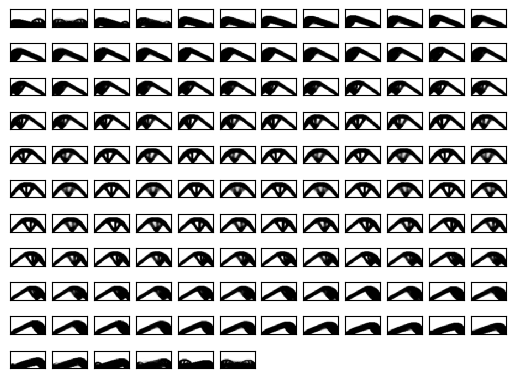

In [296]:
with torch.no_grad():
    for batch_idx, (data, _) in enumerate(input_loader):
        # Move data to GPU if available
        data = data.cuda()
        restored = vae.forward(data)[0]

        pd.DataFrame(data.cpu().view(64, 32)).to_csv(f'{reconstructed_dir}/{batch_idx}_data.csv', index=False, header=False)
        pd.DataFrame(restored.cpu().view(64, 32)).to_csv(f'{reconstructed_dir}/{batch_idx}_rest.csv', index=False, header=False)


        # save_image(data.view(1, 1, 64, 32), f'./vae_output/{batch_idx}_data' + '.png')
        # save_image(restored.view(1, 1, 64, 32), f'./vae_output/{batch_idx}_restored' + '.png')

from csv2fig import csv2fig
csv2fig(reconstructed_dir, reconstructed_dir, False)